### Task 1: Dataset Generation & Preprocessing

In [2]:
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler

# 1. Generate synthetic datasets
# Dataset A: Isotropic/Spherical blobs
X_a, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=42)

# Dataset B: Non-spherical moon shapes
X_b, _ = make_moons(n_samples=300, noise=0.05, random_state=42)

# 2. Normalize features using StandardScaler
scaler = StandardScaler()
X_a_scaled = scaler.fit_transform(X_a)
X_b_scaled = scaler.fit_transform(X_b)

### Task 2: K-Means Clustering

#### Part 1: Apply K-Means on Dataset A

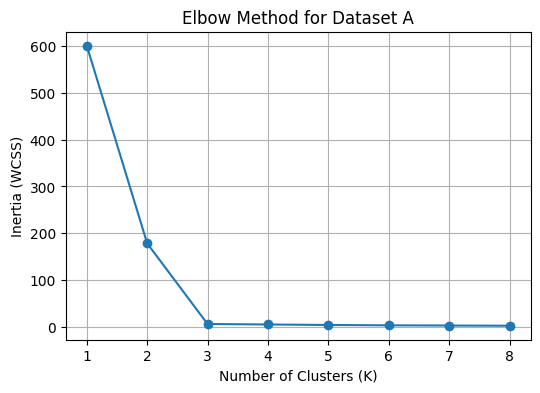

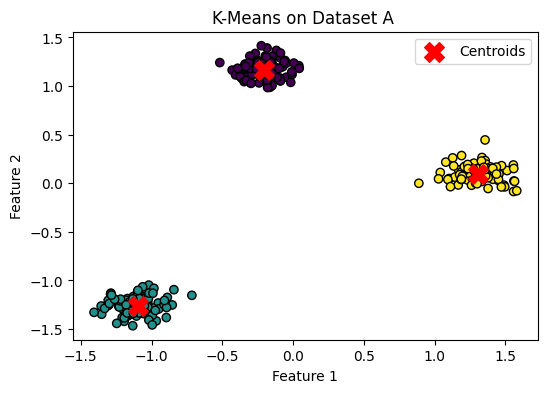

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


# 1. Elbow Method to find optimal K (K in [1, 8])
inertia_values = []
k_range = range(1, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_a_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot Inertia vs. K
plt.figure(figsize=(6, 4))
plt.plot(k_range, inertia_values, marker='o')
plt.title("Elbow Method for Dataset A")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.grid(True)
plt.show()

# 2. Fit K-Means with chosen K (K=3 based on elbow plot)
optimal_k = 3
kmeans_a = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
labels_a = kmeans_a.fit_predict(X_a_scaled)
centroids_a = kmeans_a.cluster_centers_

# 3. Plot clusters with centroids
plt.figure(figsize=(6, 4))
plt.scatter(X_a_scaled[:, 0], X_a_scaled[:, 1], c=labels_a, cmap='viridis', edgecolors='k')
plt.scatter(centroids_a[:, 0], centroids_a[:, 1], c='red', s=200, marker='X', label='Centroids')
plt.title("K-Means on Dataset A ")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

#### Part 2: Apply K-Means on Dataset B

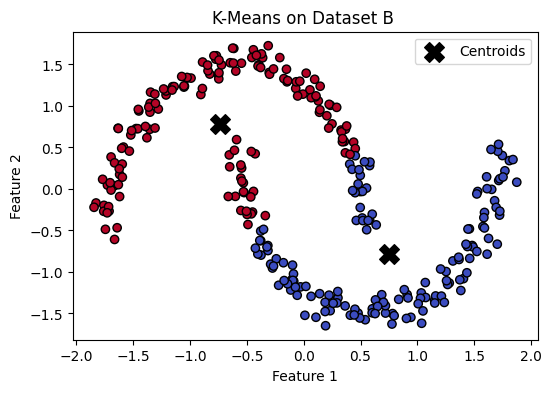

In [4]:
# Fit K-Means on Dataset B
kmeans_b = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_b = kmeans_b.fit_predict(X_b_scaled)
centroids_b = kmeans_b.cluster_centers_

# Plot clusters with centroids
plt.figure(figsize=(6, 4))
plt.scatter(X_b_scaled[:, 0], X_b_scaled[:, 1], c=labels_b, cmap='coolwarm', edgecolors='k')
plt.scatter(centroids_b[:, 0], centroids_b[:, 1], c='black', s=200, marker='X', label='Centroids')
plt.title("K-Means on Dataset B ")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

### Observation on Task 2

1. Why K=3 was chosen for Dataset A:
* In Dataset A, the Elbow Method showed a sharp drop in Inertia from K=1 to K=3, followed by a very flat line after K=3. The "elbow" bend appears distinctly at K=3, matching the 3 spherical clusters created in Task 1.

2. Why K=2 was used for Dataset B:
* Dataset B (make_moons) naturally consists of two intertwined crescent/moon shapes. Therefore, K=2 was selected to test if K-Means could separate these two visual groups.

3. K-Means fails on Dataset B:
* Spherical Assumption: K-Means assumes that all clusters are spherical (round) and convex.
* Distance-Based Boundaries: The algorithm partitions data using straight, linear boundaries based on Euclidean distance to cluster centroids.
* Result: Because the two moons are curved and wrapped around each other, a straight line cannot separate them. Instead of following the curves, K-Means simply cuts both moons in half, assigning parts of both shapes to each cluster.

### Task 3: Agglomerative Hierarchical Clustering

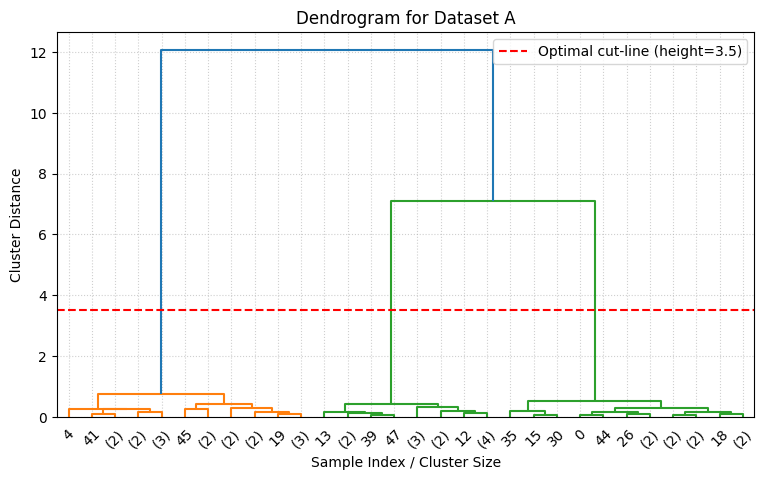

In [7]:
# Dendrogram and Optimal Cut-Line Height

import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Sample 50 points from Dataset A for clear dendrogram visualization
np.random.seed(42)
sample_indices = np.random.choice(X_a_scaled.shape[0], size=50, replace=False)
X_a_sample = X_a_scaled[sample_indices]

# Compute hierarchical clustering using the Ward linkage method
linked_matrix = linkage(X_a_sample, method='ward')

# Plot the dendrogram
plt.figure(figsize=(9, 5))
dendrogram(linked_matrix, truncate_mode='lastp', p=30, show_leaf_counts=True)

# 2. Draw optimal horizontal cut-line height at distance = 3.5
optimal_cut_height = 3.5
plt.axhline(y=optimal_cut_height, color='red', linestyle='--', 
            label=f'Optimal cut-line (height={optimal_cut_height})')

plt.title("Dendrogram for Dataset A")
plt.xlabel("Sample Index / Cluster Size")
plt.ylabel("Cluster Distance")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

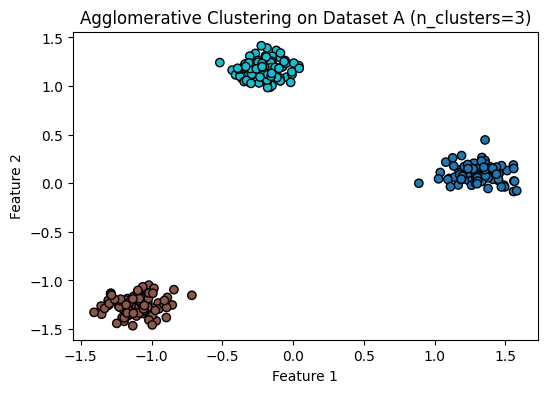

In [8]:
# Fit AgglomerativeClustering and Plot Clusters

from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt

# 1. Fit AgglomerativeClustering with 3 clusters and Ward linkage on Dataset A
agg_model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
agg_labels = agg_model.fit_predict(X_a_scaled)

# 2. Plot the resulting clusters
plt.figure(figsize=(6, 4))
plt.scatter(X_a_scaled[:, 0], X_a_scaled[:, 1], c=agg_labels, cmap='tab10', edgecolors='k')
plt.title("Agglomerative Clustering on Dataset A (n_clusters=3)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### Detailed Analysis of Task 3: Agglomerative Hierarchical Clustering

#### 1. Concept and Linkage Method:
* Agglomerative Clustering is a bottom-up approach where each data point starts as its own individual cluster.
* At each step, the two closest clusters are merged based on a linkage criterion.
* Ward's linkage was used because it minimizes the total within-cluster variance. It naturally favors compact, spherical clusters, which matches the isotropic distribution of Dataset A.

#### 2. Dendrogram and Optimal Cut-Line:
* Sampling 50 points prevented visual clutter at the bottom of the tree while preserving the true cluster hierarchy.
* The dendrogram shows two main merge levels: one at height ~12 (merging into a single root) and another at height ~7.1.
* The largest vertical gap without any horizontal lines is between heights 2.0 and 7.0.
* Placing the cut-line at height 3.5 slices through exactly 3 vertical branches, proving that the optimal number of clusters is 3.

#### 3. Clustering Results:
* Slicing at K=3 cleanly separated all 300 data points of Dataset A into three distinct, non-overlapping groups (cyan, navy, and brown).
* The clustering matches the ground truth parameters set during data generation (centers=3).

### Task 4: Density-Based Clustering (DBSCAN)

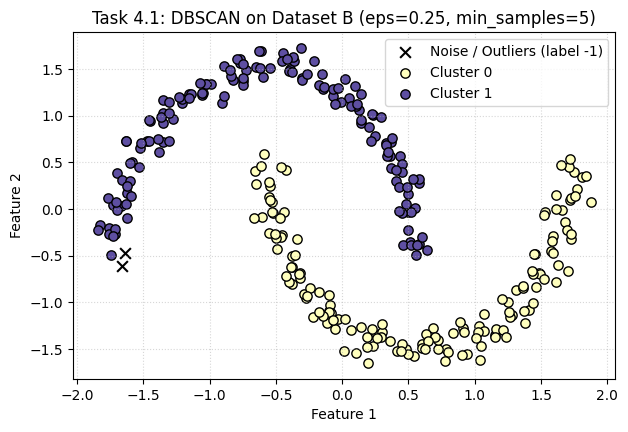

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# 1. Apply DBSCAN on Dataset B with tuned hyperparameters
# On standardized make_moons data, eps=0.20 and min_samples=5 properly separate the two moons
dbscan_model = DBSCAN(eps=0.20, min_samples=5)
db_labels = dbscan_model.fit_predict(X_b_scaled)

# 2. Plot clusters and highlight noise/outlier points (assigned label -1)
plt.figure(figsize=(7, 4.5))

unique_labels = np.unique(db_labels)
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

for label, color in zip(unique_labels, colors):
    if label == -1:
        # Highlight noise/outlier points in black with 'x' markers
        plt.scatter(X_b_scaled[db_labels == label, 0], X_b_scaled[db_labels == label, 1],
                    color='black', marker='x', s=60, label='Noise / Outliers (label -1)')
    else:
        # Clustered points with circles
        plt.scatter(X_b_scaled[db_labels == label, 0], X_b_scaled[db_labels == label, 1],
                    color=color, marker='o', edgecolors='k', s=45, label=f'Cluster {label}')

plt.title("Task 4.1: DBSCAN on Dataset B (eps=0.2, min_samples=5)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

### Task 4 Observation: Analysis of DBSCAN Results

1. Successful Identification of Complex Shapes:
* DBSCAN successfully traces the two interlocked moon shapes and assigns them into two distinct groups: Cluster 0 and Cluster 1.
* It succeeds because it uses density-based connectivity instead of calculating distances to a geometric centroid.

2. Handling Noise Points:
* The points with label -1 (marked with black 'X' symbols) are correctly identified as noise/outliers.
* With `eps=0.20` and `min_samples=5`, these isolated points in sparse areas do not have enough neighbors within the radius to meet the density threshold.

3. Comparison with K-Means and Agglomerative Clustering:
* K-Means failed on this dataset because it assumes spherical clusters and separates points using straight linear lines, cutting both moons in half.
* Agglomerative Clustering with Ward linkage also failed because it tries to minimize within-cluster variance, which forces clusters to be compact and round.
* DBSCAN succeeds because it follows local high-density pathways along the curves regardless of cluster shape.